In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../ML-Aided-NR-V2X-QoS-Predictions/dataset.csv')
df.drop_duplicates(inplace=True)

In [2]:
df.isna().sum()

Unnamed: 0       0
X                0
Y                0
throughput       0
mcs              0
distance       103
pktsize          0
delay            0
jitter        3138
sinr             0
power            0
dlpathloss       0
pdr              0
dtype: int64

NameError: name 'to' is not defined

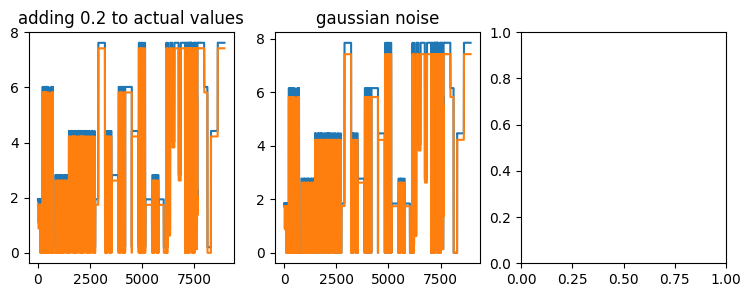

In [ ]:
tp = df['throughput'].copy()

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(9,3))

# tp_noise = tp + tp * np.std(tp) 
tp_noise = tp + 0.2
ax[0].plot(tp_noise)
ax[0].plot(tp)
ax[0].set_title("adding 0.2 to actual values")

tp_noise = tp + tp * np.std(tp) * 0.02
ax[1].plot(tp_noise)
ax[1].plot(tp)
ax[1].set_title("gaussian noise")

tp_x = tp + tp * 0.02
plt.show()

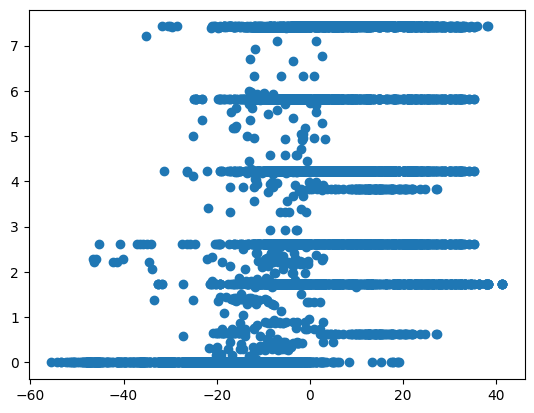

In [7]:
tp = df['throughput'].shift(periods=5)

tp = tp[5:]
# tp.head(10)
sinr = df['sinr']
sinr = sinr[5:]
# print(sinr.shape)
plt.scatter(sinr, tp)
plt.savefig('../results/tp_vs_sinr.png')
plt.show()